# R8 · Pan-cancer programme queries (Fig 8)

Four breast gene programmes are searched as queries in five tumour sections (breast, lung, pancreas, brain, skin),
seeds 0–4:
* **Exemplar per programme:** the breast seed-0 index tile with the largest robust co-variation on the programme genes.
  R_S is its correlation and q_g its variance quantiles.
* **Query per section and seed:** diag(σ) R_S diag(σ), with σ quantile-matched to the section.
* **Hits:** 5 % of the index tiles, from Spindle-naive (exact d_B^S) and Spindle, with variances-only (D) and
  tile-score (X) controls. Readouts: gain in match to R_S, Cliff's δ, co-variation lift and Jaccard indices.
* **Seed 0:** every index tile's d_B^S to each query, for the gradient maps.

The rules are fixed in `experiments/common/pan_cancer.py`.

* **Prerequisites:** `R0_index_cache.ipynb`.
* **Writes:** `results/pan_cancer/`:
  * `exemplar.{csv,npz}`
  * `per_dataset/<key>/seed<s>_{programs,hits}.csv`
  * `per_dataset/<key>/seed0_gradient.npz`
  * `programs.csv` (summary over seeds)
* **Skips** existing outputs (`FORCE = True` redoes all).
* **Runtime / memory:** about 30–60 min on one core; peak about 6 GB (brain_cancer).

In [1]:
import gc
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import data
import pan_cancer as pc
import results_io as rio
import sections as sx

FORCE = False
TOPIC = "pan_cancer"
OUT = rio.topic(TOPIC)
print(data.stamp())


def save_npz(arrays, file, description):
    path = OUT / file
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, **arrays)
    rio.register(TOPIC, path, description)

{'tag': 'method-v2', 'describe': 'method-v2-dirty', 'commit': '8040f91'}


## Exemplars (breast, seed 0)

In [2]:
if FORCE or not (OUT / "exemplar.csv").exists() or not (OUT / "exemplar.npz").exists():
    E, arrays = pc.exemplars()
    rio.write_csv(E, TOPIC, "exemplar.csv", "one exemplar tile per programme: genes, c, mean r, variance quantiles q")
    save_npz(arrays, "exemplar.npz", "R_S, q and box of each exemplar; breast cells")
    del arrays
    gc.collect()
E = pd.read_csv(OUT / "exemplar.csv")
Z = dict(np.load(OUT / "exemplar.npz"))
E

Cytotoxic_T: tile 1120 (179 cells), c 0.404, mean r 0.121, 191 robust tiles, q [0.8  0.7  0.83 0.87 0.79 0.53 0.73 0.87 0.81 0.69]
Myeloid: tile 832 (180 cells), c 0.654, mean r 0.412, 270 robust tiles, q [0.79 0.69 0.83 0.81 0.74]
Stromal_Perivascular: tile 947 (90 cells), c 0.511, mean r 0.284, 355 robust tiles, q [0.19 0.11 0.76 0.86 0.61]
B_Plasma: tile 389 (150 cells), c 0.407, mean r 0.174, 112 robust tiles, q [0.76 0.96 0.97 0.95 0.95]
wrote results/pan_cancer/exemplar.csv: 4 rows


,program,genes,n_genes,tile,n_cells,c,mean_r,n_robust,q,tag
0,Cytotoxic_T,CD3D CD3E CD8A NKG7 GNLY GZMA GZMB PRF1 KLRD1 ...,10,1120,179,0.403952,0.120997,191,0.803 0.702 0.829 0.866 0.786 0.527 0.734 0.87...,method-v2
1,Myeloid,CD68 CD163 CD14 AIF1 MNDA,5,832,180,0.654132,0.412213,270,0.791 0.692 0.829 0.805 0.743,method-v2
2,Stromal_Perivascular,ACTA2 MYH11 PDGFRB PDGFRA FBLN1,5,947,90,0.511000,0.283819,355,0.187 0.105 0.755 0.860 0.611,method-v2
3,B_Plasma,MS4A1 CD79A MZB1 TNFRSF17 DERL3,5,389,150,0.406669,0.174434,112,0.765 0.960 0.970 0.949 0.951,method-v2


## Queries in each section and seed, and the seed-0 gradients

In [3]:
for key in pc.KEYS:
    for seed in data.SEEDS:
        d = f"per_dataset/{key}"
        grad = seed == data.EXAMPLE_SEED
        need = [OUT / d / f"seed{seed}_{n}.csv" for n in ("programs", "hits")]
        if grad:
            need.append(OUT / d / f"seed{seed}_gradient.npz")
        if not FORCE and all(p.exists() for p in need):
            print(f"{key} seed {seed}: exists, skipped")
            continue
        S = sx.load(key, seed, parts=("layout", "naive_partial", "spindle_partial"))
        T, H = pc.section(S, seed, E, Z)
        rio.write_csv(T, TOPIC, f"{d}/seed{seed}_programs.csv",
                      "programme x method: hits returned, gain, delta, co-variation lift, Jaccard")
        rio.write_csv(H, TOPIC, f"{d}/seed{seed}_hits.csv", "every hit: rank, tile, correlation gap, tile score")
        print(T[["program", "method", "n_returned", "gain", "delta", "lift", "jacc_naive_partial", "jacc_D"]]
              .round(3).to_string(index=False))
        if grad:
            save_npz(pc.gradient(S, E, Z), f"{d}/seed{seed}_gradient.npz",
                     "seed 0: cells, index tile centres/sides, exact d_B^S of every index tile to each query")
        del S, T, H
        gc.collect()
        print(f"{key} seed {seed}: done; peak memory so far {rio.peak_rss_gb():.1f} GB", flush=True)

wrote results/pan_cancer/per_dataset/breast_cancer/seed0_programs.csv: 16 rows
wrote results/pan_cancer/per_dataset/breast_cancer/seed0_hits.csv: 1106 rows
             program          method  n_returned   gain  delta   lift  jacc_naive_partial  jacc_D
         Cytotoxic_T   naive_partial          92  0.046  0.124  0.053               1.000   0.415
         Cytotoxic_T               D          92  0.039  0.195 -0.006               0.415   1.000
         Cytotoxic_T spindle_partial           2  0.052  0.153 -0.007               0.022   0.022
         Cytotoxic_T               X          92 -0.020  1.000 -0.030               0.000   0.000
             Myeloid   naive_partial          92  0.085  0.325  0.056               1.000   0.305
             Myeloid               D          92  0.035  0.446 -0.022               0.305   1.000
             Myeloid spindle_partial           0    NaN    NaN    NaN               0.000   0.000
             Myeloid               X          92  0.050  1.0

/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/NAShome/ghoss18/spindle_dev/experiments/common/sections.py:133: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * u / (len(x) * len(y)) - 1
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


breast_cancer Myeloid: d 0.000-4.708
breast_cancer Stromal_Perivascular: d 0.003-4.342
breast_cancer B_Plasma: d 0.001-5.442
breast_cancer seed 0: done; peak memory so far 1.4 GB


/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/NAShome/ghoss18/spindle_dev/experiments/common/sections.py:133: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * u / (len(x) * len(y)) - 1
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


wrote results/pan_cancer/per_dataset/breast_cancer/seed1_programs.csv: 16 rows
wrote results/pan_cancer/per_dataset/breast_cancer/seed1_hits.csv: 1134 rows
             program          method  n_returned   gain  delta   lift  jacc_naive_partial  jacc_D
         Cytotoxic_T   naive_partial          92  0.046  0.096  0.070               1.000   0.373
         Cytotoxic_T               D          92  0.040  0.199  0.001               0.373   1.000
         Cytotoxic_T spindle_partial           0    NaN    NaN    NaN               0.000   0.000
         Cytotoxic_T               X          92 -0.020  1.000 -0.027               0.000   0.000
             Myeloid   naive_partial          92  0.088  0.351  0.058               1.000   0.314
             Myeloid               D          92  0.041  0.470 -0.025               0.314   1.000
             Myeloid spindle_partial           1  0.025  0.776 -0.071               0.011   0.011
             Myeloid               X          92  0.052  1.0

/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/NAShome/ghoss18/spindle_dev/experiments/common/sections.py:133: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * u / (len(x) * len(y)) - 1
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


wrote results/pan_cancer/per_dataset/breast_cancer/seed2_programs.csv: 16 rows
wrote results/pan_cancer/per_dataset/breast_cancer/seed2_hits.csv: 1160 rows
             program          method  n_returned   gain  delta   lift  jacc_naive_partial  jacc_D
         Cytotoxic_T   naive_partial          92  0.045  0.137  0.058               1.000   0.363
         Cytotoxic_T               D          92  0.038  0.238 -0.025               0.363   1.000
         Cytotoxic_T spindle_partial           0    NaN    NaN    NaN               0.000   0.000
         Cytotoxic_T               X          92 -0.017  1.000 -0.030               0.000   0.000
             Myeloid   naive_partial          92  0.082  0.357  0.058               1.000   0.343
             Myeloid               D          92  0.037  0.473 -0.025               0.343   1.000
             Myeloid spindle_partial           1  0.032  0.628 -0.061               0.011   0.011
             Myeloid               X          92  0.048  1.0

/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/NAShome/ghoss18/spindle_dev/experiments/common/sections.py:133: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * u / (len(x) * len(y)) - 1
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


wrote results/pan_cancer/per_dataset/breast_cancer/seed3_programs.csv: 16 rows
wrote results/pan_cancer/per_dataset/breast_cancer/seed3_hits.csv: 1207 rows
             program          method  n_returned   gain  delta   lift  jacc_naive_partial  jacc_D
         Cytotoxic_T   naive_partial          92  0.045  0.118  0.054               1.000   0.373
         Cytotoxic_T               D          92  0.038  0.219 -0.025               0.373   1.000
         Cytotoxic_T spindle_partial          13  0.055  0.121 -0.001               0.129   0.094
         Cytotoxic_T               X          92 -0.022  1.000 -0.029               0.000   0.000
             Myeloid   naive_partial          92  0.089  0.342  0.062               1.000   0.296
             Myeloid               D          92  0.044  0.456 -0.016               0.296   1.000
             Myeloid spindle_partial          89  0.069  0.406  0.042               0.414   0.321
             Myeloid               X          92  0.054  1.0

/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/NAShome/ghoss18/spindle_dev/experiments/common/sections.py:133: RuntimeWarning: invalid value encountered in scalar divide
  return 2 * u / (len(x) * len(y)) - 1
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


wrote results/pan_cancer/per_dataset/breast_cancer/seed4_programs.csv: 16 rows
wrote results/pan_cancer/per_dataset/breast_cancer/seed4_hits.csv: 1146 rows
             program          method  n_returned   gain  delta   lift  jacc_naive_partial  jacc_D
         Cytotoxic_T   naive_partial          92  0.045  0.125  0.051               1.000   0.343
         Cytotoxic_T               D          92  0.037  0.220 -0.023               0.343   1.000
         Cytotoxic_T spindle_partial           7  0.053  0.031  0.011               0.076   0.053
         Cytotoxic_T               X          92 -0.021  1.000 -0.033               0.000   0.000
             Myeloid   naive_partial          92  0.091  0.327  0.064               1.000   0.278
             Myeloid               D          92  0.037  0.443 -0.025               0.278   1.000
             Myeloid spindle_partial           1  0.024  0.789 -0.071               0.011   0.011
             Myeloid               X          92  0.046  1.0

## Summary over seeds

In [4]:
g = pd.concat([pd.read_csv(OUT / f"per_dataset/{k}/seed{s}_programs.csv") for k in pc.KEYS for s in data.SEEDS],
              ignore_index=True)
P = pc.summary(g)
rio.write_csv(P, TOPIC, "programs.csv", "per section, programme and method: mean and s.d. over seeds; absent flag")
P[["key", "program", "method", "gain", "gain_sd", "delta", "lift", "jacc_naive_partial", "jacc_D", "n_returned",
   "absent"]].round(3)

wrote results/pan_cancer/programs.csv: 80 rows


,key,program,method,gain,gain_sd,delta,lift,jacc_naive_partial,jacc_D,n_returned,absent
0,breast_cancer,Cytotoxic_T,naive_partial,0.045,0.001,0.120,0.057,1.000,0.374,92.0,False
1,breast_cancer,Cytotoxic_T,D,0.038,0.001,0.214,-0.016,0.374,1.000,92.0,False
2,breast_cancer,Cytotoxic_T,spindle_partial,0.053,0.002,0.102,0.001,0.045,0.034,4.4,False
3,breast_cancer,Cytotoxic_T,X,-0.020,0.002,1.000,-0.030,0.000,0.000,92.0,False
4,breast_cancer,Myeloid,naive_partial,0.087,0.003,0.340,0.060,1.000,0.307,92.0,False
...,...,...,...,...,...,...,...,...,...,...,...
75,skin_melanoma,Stromal_Perivascular,X,0.060,0.002,1.000,0.061,0.000,0.000,42.0,False
76,skin_melanoma,B_Plasma,naive_partial,0.000,0.000,-0.149,-0.021,1.000,0.860,42.0,True
77,skin_melanoma,B_Plasma,D,0.000,0.000,-0.250,-0.036,0.860,1.000,42.0,True
78,skin_melanoma,B_Plasma,spindle_partial,0.000,0.000,-0.169,-0.039,0.821,0.773,39.6,True


## Quick look (not saved)

/tmp/ipykernel_1885698/3362177221.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


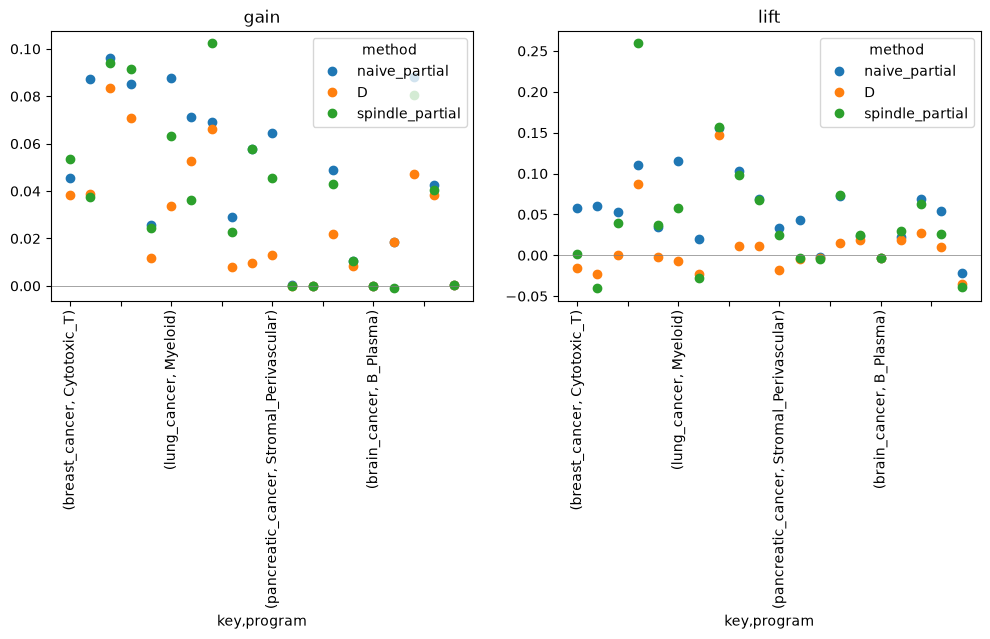

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, col in zip(ax, ("gain", "lift")):
    v = P[P.method.isin(["naive_partial", "spindle_partial", "D"])].pivot_table(
        index=["key", "program"], columns="method", values=col, sort=False)
    v.plot(ax=a, marker="o", ls="", rot=90, title=col)
    a.axhline(0, color="grey", lw=0.5)
plt.tight_layout()
plt.show()

In [6]:
rio.write_manifest(TOPIC, "R8_pan_cancer.ipynb", inputs=["results/_cache"], notes="Fig 8.")

wrote results/pan_cancer/manifest.json: 58 files; peak memory 11.13 GB


{'topic': 'pan_cancer',
 'notebook': 'R8_pan_cancer.ipynb',
 'date': '2026-10-31 23:54',
 'tag': 'method-v2',
 'describe': 'method-v2-dirty',
 'commit': '8040f91',
 'inputs': ['results/_cache'],
 'peak_rss_gb': 11.13,
 'notes': 'Fig 8.',
 'files': {'exemplar.csv': {'description': 'one exemplar tile per programme: genes, c, mean r, variance quantiles q',
   'rows': 4,
   'bytes': 655},
  'exemplar.npz': {'description': 'R_S, q and box of each exemplar; breast cells',
   'rows': None,
   'bytes': 1104544},
  'per_dataset/brain_cancer/seed0_gradient.npz': {'description': 'seed 0: cells, index tile centres/sides, exact d_B^S of every index tile to each query',
   'rows': None,
   'bytes': 5804963},
  'per_dataset/brain_cancer/seed0_hits.csv': {'description': 'every hit: rank, tile, correlation gap, tile score',
   'rows': 6836,
   'bytes': 570181},
  'per_dataset/brain_cancer/seed0_programs.csv': {'description': 'programme x method: hits returned, gain, delta, co-variation lift, Jaccard',
